# Cobertura de Mamografia (50–69 anos) — PNS 2019

Análise da variação da cobertura de mamografia entre UFs e subgrupos de renda, escolaridade e cor/raça, com comparação da evolução anual de exames SUS (2020–2024).

**Fontes:**
- `subgrupos_pns_2019.csv` — PNS 2019, subgrupos por escolaridade, cor/raça e renda
- `exames_sus_2020_2024.csv` — exames de rastreamento SUS por UF e ano
- `base_uf.csv` — indicadores consolidados por UF (incidência, mortalidade, infraestrutura)

## 1. Importação e carregamento dos dados

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pns = pd.read_csv("../dados/tratados/subgrupos_pns_2019.csv")
exames = pd.read_csv("../dados/tratados/exames_sus_2020_2024.csv")
uf = pd.read_csv("../dados/tratados/base_uf.csv")

pns_mamo = pns[pns["indicador"] == "fez_ultimos_2_anos"].copy()
pns_mamo.head()

,nivel,regiao,uf_sigla,indicador,dimensao,categoria,percentual,ic95_inferior,ic95_superior,observacao
0,regiao,Norte,NaN,fez_ultimos_2_anos,escolaridade,Sem instrução e fundamental incompleto,32.5,28.8,36.4,NaN
1,regiao,Norte,NaN,fez_ultimos_2_anos,escolaridade,Fundamental completo e médio incompleto,49.6,41.3,57.8,NaN
2,regiao,Norte,NaN,fez_ultimos_2_anos,escolaridade,Médio completo e superior incompleto,52.3,46.3,58.2,NaN
3,regiao,Norte,NaN,fez_ultimos_2_anos,escolaridade,Superior completo,65.1,56.4,72.9,NaN
4,regiao,Norte,NaN,fez_ultimos_2_anos,cor_raca,Branca,50.4,43.7,57.2,NaN


## 2. Cobertura por UF (PNS 2019)

In [2]:
uf_sorted = uf[["uf_sigla", "uf_nome", "regiao", "cobertura_pns_2019",
                "cobertura_pns_2013", "var_cobertura_2013_2019"]] \
                .sort_values("cobertura_pns_2019", ascending=False)

uf_sorted

,uf_sigla,uf_nome,regiao,cobertura_pns_2019,cobertura_pns_2013,var_cobertura_2013_2019
19,SP,São Paulo,Sudeste,69.3,72.3,-3.0
16,ES,Espírito Santo,Sudeste,67.2,63.4,3.8
18,RJ,Rio de Janeiro,Sudeste,62.5,57.8,4.7
23,DF,Distrito Federal,Centro-Oeste,61.8,67.9,-6.1
8,BA,Bahia,Nordeste,60.3,57.0,3.3
21,RS,Rio Grande do Sul,Sul,59.6,62.8,-3.2
17,MG,Minas Gerais,Sudeste,58.8,62.9,-4.1
20,PR,Paraná,Sul,58.3,65.2,-6.9
22,SC,Santa Catarina,Sul,58.2,65.7,-7.5
25,MS,Mato Grosso do Sul,Centro-Oeste,57.7,53.4,4.3


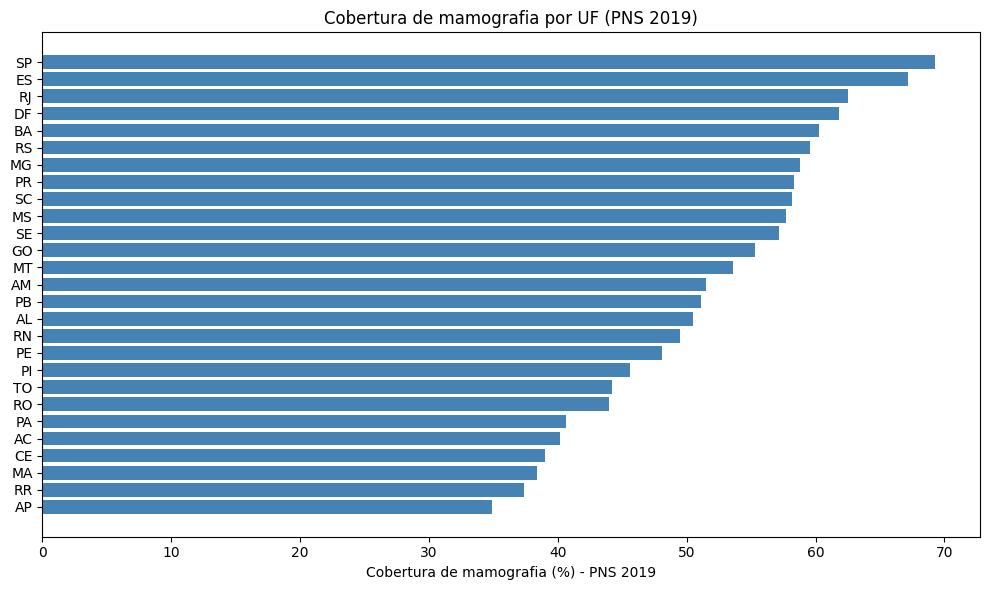

In [3]:
plt.figure(figsize=(10, 6))
plt.barh(uf_sorted["uf_sigla"], uf_sorted["cobertura_pns_2019"], color="steelblue")
plt.xlabel("Cobertura de mamografia (%) - PNS 2019")
plt.title("Cobertura de mamografia por UF (PNS 2019)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

**Observação:** UFs do Sudeste/Sul (ex. SP 69,3%, DF 61,8%, PR 58,3%) apresentam cobertura mais alta; UFs do Norte (ex. AP 34,9%, RR 37,4%, AC 40,2%) apresentam cobertura mais baixa, refletindo desigualdade regional.

## 3. Cobertura por escolaridade

In [4]:
esc = pns_mamo[pns_mamo["dimensao"] == "escolaridade"]

ordem_esc = [
    "Sem instrução e fundamental incompleto",
    "Fundamental completo e médio incompleto",
    "Médio completo e superior incompleto",
    "Superior completo",
]

pivot_esc = esc.pivot_table(index="categoria", columns="regiao", values="percentual")
pivot_esc = pivot_esc.reindex(ordem_esc)
pivot_esc

regiao,Brasil,Centro-Oeste,Nordeste,Norte,Sudeste,Sul
categoria,,,,,,
Sem instrução e fundamental incompleto,49.0,49.36,39.00,32.1375,57.06,49.850
Fundamental completo e médio incompleto,56.0,56.50,52.34,47.0500,59.10,56.325
Médio completo e superior incompleto,65.7,62.44,64.06,46.4625,68.56,67.125
Superior completo,77.8,69.88,72.78,64.5125,81.96,76.425


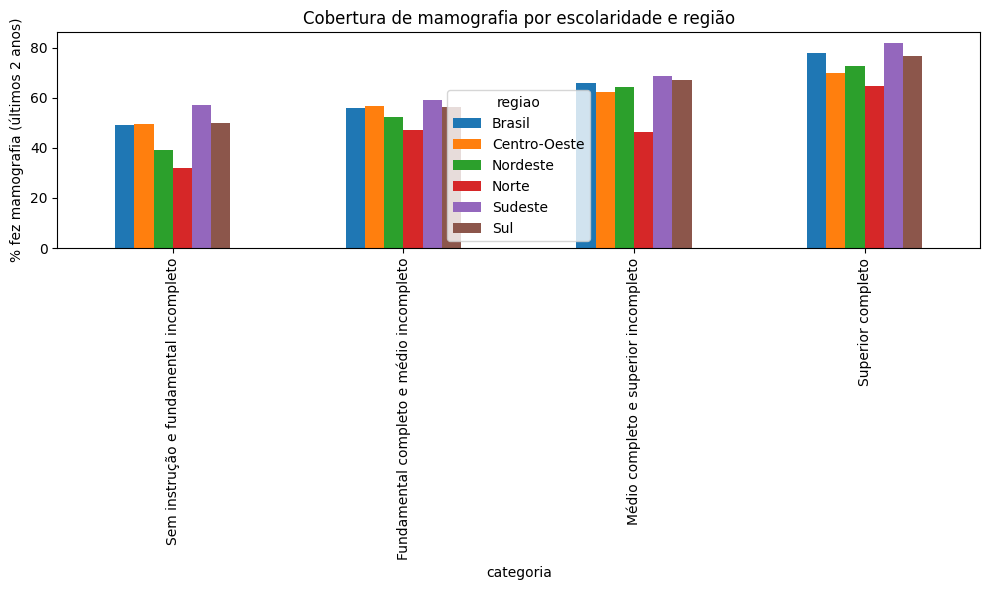

In [5]:
pivot_esc.plot(kind="bar", figsize=(10, 6))
plt.ylabel("% fez mamografia (últimos 2 anos)")
plt.title("Cobertura de mamografia por escolaridade e região")
plt.tight_layout()
plt.show()

**Padrão:** cobertura cresce de forma quase monotônica com a escolaridade — no Brasil, de 49,0% (sem instrução/fundamental incompleto) para 77,8% (superior completo), gradiente de ~29 p.p.

## 4. Cobertura por cor/raça

In [6]:
raca = pns_mamo[pns_mamo["dimensao"] == "cor_raca"]
pivot_raca = raca.pivot_table(index="categoria", columns="regiao", values="percentual")
pivot_raca

regiao,Brasil,Centro-Oeste,Nordeste,Norte,Sudeste,Sul
categoria,,,,,,
Branca,61.8,57.14,51.60,48.4625,65.90,60.05
Parda,54.4,56.24,47.87,40.1125,65.30,52.00
Preta,56.5,60.38,45.72,43.2000,58.38,64.60


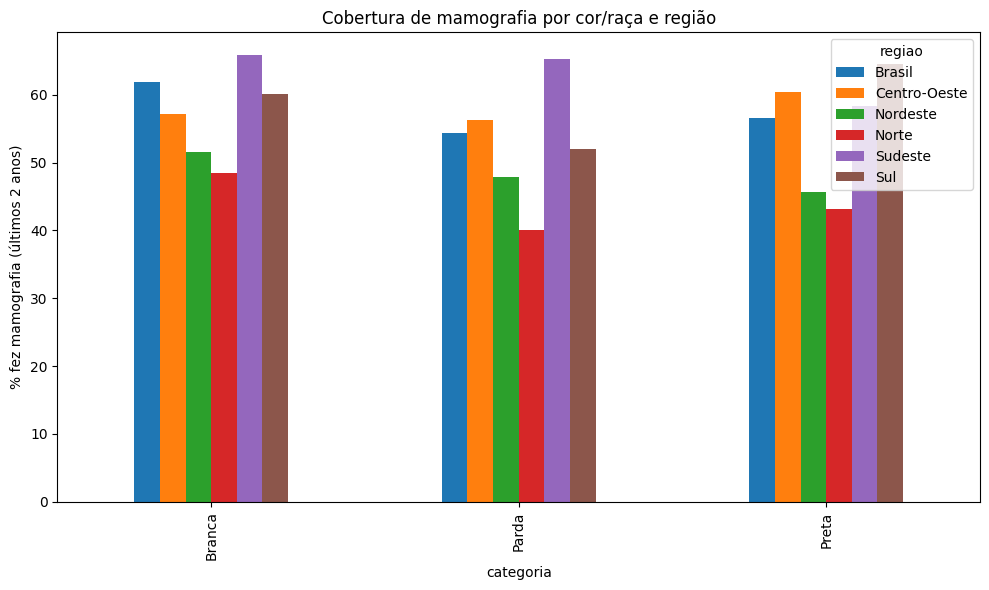

In [7]:
pivot_raca.plot(kind="bar", figsize=(10, 6))
plt.ylabel("% fez mamografia (últimos 2 anos)")
plt.title("Cobertura de mamografia por cor/raça e região")
plt.tight_layout()
plt.show()

**Padrão:** no Brasil, mulheres brancas têm cobertura maior (61,8%) do que pardas (54,4%) e pretas (56,5%). A diferença é mais acentuada em regiões como Sudeste e Sul.

## 5. Cobertura por renda

In [8]:
renda = pns_mamo[pns_mamo["dimensao"] == "rendimento"]

ordem_renda = [
    "Sem rendimento até 1/4 SM", "De 1/4 a 1/2 SM", "De 1/2 a 1 SM",
    "De 1 a 2 SM", "De 2 a 3 SM", "De 3 a 5 SM", "Mais de 5 SM",
]

pivot_renda = renda.pivot_table(index="categoria", columns="regiao", values="percentual")
pivot_renda = pivot_renda.reindex(ordem_renda)
pivot_renda

regiao,Brasil,Centro-Oeste,Nordeste,Norte,Sudeste,Sul
categoria,,,,,,
Sem rendimento até 1/4 SM,42.9,53.66,36.810000,25.7250,52.44,45.275
De 1/4 a 1/2 SM,44.3,51.00,37.770000,33.1125,54.64,52.825
De 1/2 a 1 SM,49.7,46.38,43.690000,37.5750,57.10,48.550
De 1 a 2 SM,59.8,58.22,59.390000,45.5375,61.38,58.075
De 2 a 3 SM,69.1,60.82,68.550000,58.1875,72.18,64.225
De 3 a 5 SM,79.9,69.58,79.144444,57.4750,87.12,73.750
Mais de 5 SM,83.7,75.92,78.280000,87.2500,87.50,79.375


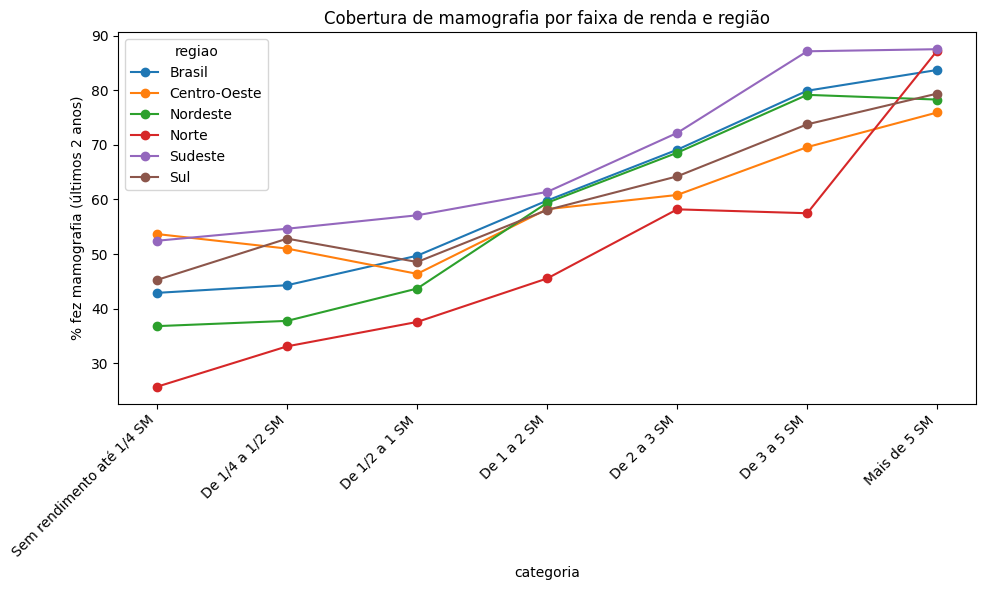

In [9]:
pivot_renda.plot(kind="line", marker="o", figsize=(10, 6))
plt.ylabel("% fez mamografia (últimos 2 anos)")
plt.title("Cobertura de mamografia por faixa de renda e região")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**Padrão:** o gradiente de renda é o mais forte dos três — no Brasil, varia de 42,9% (sem rendimento a 1/4 SM) até 83,7% (mais de 5 SM), diferença de ~41 p.p.

## 6. Relação entre cobertura (PNS) e oferta de exames/equipamentos (SUS)

In [10]:
infra = uf[["uf_sigla", "cobertura_pns_2019", "mamografos_por_100mil_mulheres",
            "exames_sus_2024", "pct_tratados_ate_60_dias"]]

corr = infra[["cobertura_pns_2019", "mamografos_por_100mil_mulheres",
              "pct_tratados_ate_60_dias"]].corr()
corr

,cobertura_pns_2019,mamografos_por_100mil_mulheres,pct_tratados_ate_60_dias
cobertura_pns_2019,1.000000,0.178627,0.111842
mamografos_por_100mil_mulheres,0.178627,1.000000,-0.110605
pct_tratados_ate_60_dias,0.111842,-0.110605,1.000000


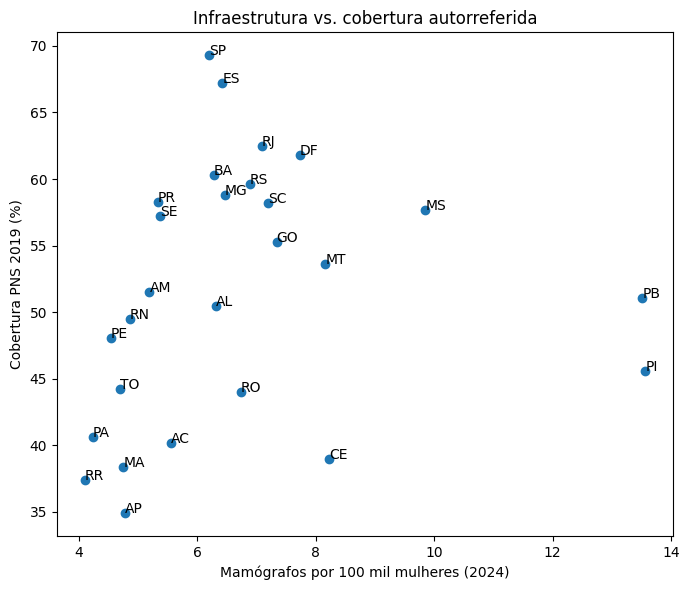

In [11]:
plt.figure(figsize=(7, 6))
plt.scatter(infra["mamografos_por_100mil_mulheres"], infra["cobertura_pns_2019"])
for _, row in infra.iterrows():
    plt.annotate(row["uf_sigla"],
                 (row["mamografos_por_100mil_mulheres"], row["cobertura_pns_2019"]))
plt.xlabel("Mamógrafos por 100 mil mulheres (2024)")
plt.ylabel("Cobertura PNS 2019 (%)")
plt.title("Infraestrutura vs. cobertura autorreferida")
plt.tight_layout()
plt.show()

## 7. Evolução anual de exames SUS por região (2020–2024)

In [12]:
exames_regiao_ano = exames.groupby(["regiao", "ano"])["n_mamografias_rastreamento_50_69"] \
    .sum().reset_index()

pivot_ano = exames_regiao_ano.pivot(index="ano", columns="regiao",
                                     values="n_mamografias_rastreamento_50_69")
pivot_ano

regiao,Centro-Oeste,Nordeste,Norte,Sudeste,Sul
ano,,,,,
2020,51969,323276,51121,753908,293003
2021,87969,518680,65370,994784,388480
2022,122151,586409,82912,1261044,491241
2023,133437,644795,87211,1278320,517284
2024,127665,673078,89352,1299258,464845


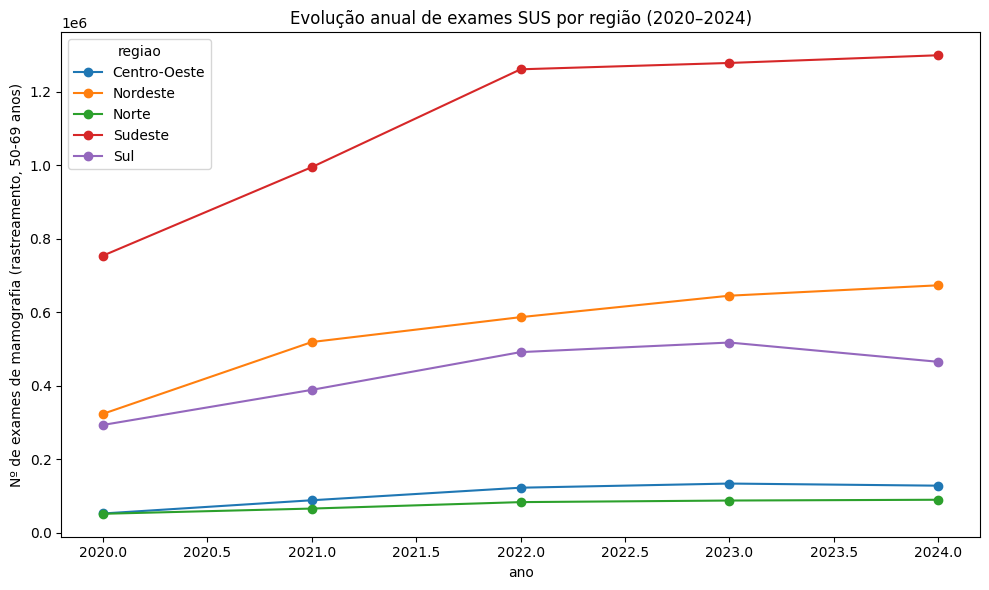

In [13]:
pivot_ano.plot(kind="line", marker="o", figsize=(10, 6))
plt.ylabel("Nº de exames de mamografia (rastreamento, 50-69 anos)")
plt.title("Evolução anual de exames SUS por região (2020–2024)")
plt.tight_layout()
plt.show()

## 8. Crescimento acumulado 2020 → 2024 por região

In [14]:
crescimento = ((pivot_ano.loc[2024] - pivot_ano.loc[2020]) / pivot_ano.loc[2020] * 100) \
    .sort_values(ascending=False)
crescimento

regiao
Centro-Oeste    145.656064
Nordeste        108.205372
Norte            74.785313
Sudeste          72.336412
Sul              58.648546
dtype: float64

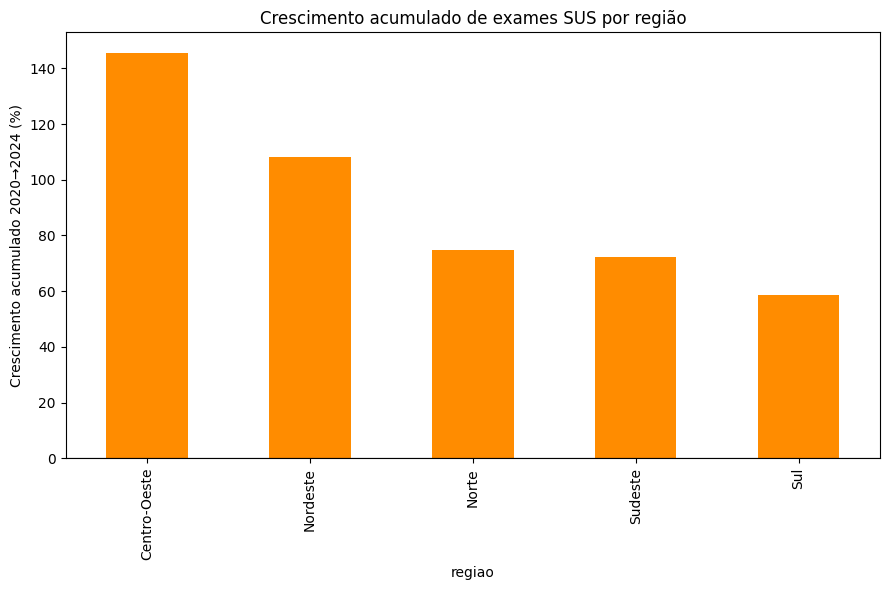

In [15]:
plt.figure(figsize=(9, 6))
crescimento.plot(kind="bar", color="darkorange")
plt.ylabel("Crescimento acumulado 2020→2024 (%)")
plt.title("Crescimento acumulado de exames SUS por região")
plt.axhline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

**Comparação entre anos e regiões:**
- **Centro-Oeste** e **Nordeste** têm o maior crescimento acumulado (acima de 100%), partindo de uma base de exames menor em 2020.
- **Sudeste** e **Sul** crescem de forma mais moderada e, em alguns casos (ex. Sul, Minas Gerais), apresentam **queda entre 2023 e 2024** — possível reflexo de normalização pós-pandemia ou ajuste de demanda reprimida.
- O crescimento mais acelerado em regiões historicamente com menor cobertura (Norte/Nordeste) indica uma trajetória de redução de desigualdade regional no acesso a exames pelo SUS, embora os níveis absolutos ainda sejam muito inferiores aos do Sudeste.

## 9. Síntese dos achados

| Dimensão | Gradiente observado (Brasil) | Amplitude |
|---|---|---|
| Escolaridade | 49,0% (sem instrução) → 77,8% (superior) | ~29 p.p. |
| Cor/raça | 54,4% (parda) → 61,8% (branca) | ~7 p.p. |
| Renda | 42,9% (sem rend. a ¼ SM) → 83,7% (>5 SM) | ~41 p.p. |
| UF (Norte vs. Sudeste) | ~35–40% (Norte) → ~65–70% (Sudeste/DF) | ~30 p.p. |

**Conclusão:** a renda é o fator de maior desigualdade na cobertura de mamografia, seguido pela escolaridade e pela desigualdade regional (Norte/Nordeste vs. Sul/Sudeste). A diferença por cor/raça é mais modesta, mas consistente — mulheres pretas e pardas sempre abaixo das brancas na maioria das regiões. A série 2020–2024 de exames SUS mostra convergência parcial, com Nordeste e Centro-Oeste crescendo mais rápido, embora ainda distantes dos volumes absolutos do Sudeste.